# Eigenfaces Face Recognition Lab

This notebook covers Experiments 1–8 from the lab manual.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
from google.colab import files
uploaded=files.upload()  # Upload Class_Images.zip
import zipfile, os
zip_name=[k for k in uploaded if k.endswith('.zip')][0]
with zipfile.ZipFile(zip_name) as z: z.extractall('data')
print(os.listdir('data'))

Saving Class_Images.zip to Class_Images (4).zip
['class_images']


In [ ]:
import os
for root, dirs,files in os.walk("data"):
  print(root)
  for f in files[:5]:
    print("   ",f)

data
data/class_images
data/class_images/smiling_cropped
    face21.jpg
    face10.jpg
    face7.jpg
    face31.jpg
    face20.jpg
data/class_images/nonsmiling_cropped
    face21.jpg
    face10.jpg
    face7.jpg
    face31.jpg
    face20.jpg
data/class_images/group
    IMG_5888.JPG
    IMG_5898.JPG
    IMG_5897.JPG
    IMG_5895.JPG
    IMG_5890.JPG


In [ ]:
import cv2

IMAGE_SIZE = (64,64)

base_path = "data/class_images"

train_folder = os.path.join(base_path, "nonsmiling_cropped")
test_folder = os.path.join(base_path, "smiling_cropped")

train_images = []
train_labels = []
test_images = []
test_labels = []

#Training Images

for filename in sorted(os.listdir(train_folder)):
  path = os.path.join(train_folder,filename)
  image = cv2.imread(path,cv2.IMREAD_GRAYSCALE)
  if image is None:
    continue
  image = cv2.resize(image, IMAGE_SIZE)
  train_images.append(image.flatten())
  label = os.path.splitext(filename)[0]
  train_labels.append(label)

#Testing Images

for filename in sorted(os.listdir(test_folder)):
  path = os.path.join(test_folder,filename)
  image = cv2.imread(path,cv2.IMREAD_GRAYSCALE)
  if image is None:
    continue
  image = cv2.resize(image, IMAGE_SIZE)
  test_images.append(image.flatten())
  label = os.path.splitext(filename)[0]
  test_labels.append(label)

train_images = np.array(train_images)
test_images = np.array(test_images)

print("Training images :", train_images.shape)
print("Test images :", test_images.shape)


Training images : (36, 4096)
Test images : (36, 4096)


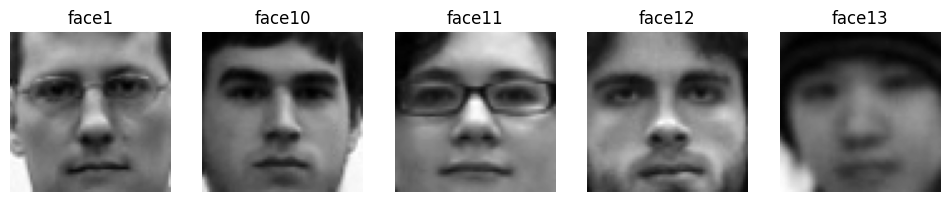

In [ ]:
plt.figure(figsize=(12,4))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(train_images[i].reshape(64,64),cmap='gray')
  plt.title(train_labels[i])
  plt.axis('off')
plt.show()

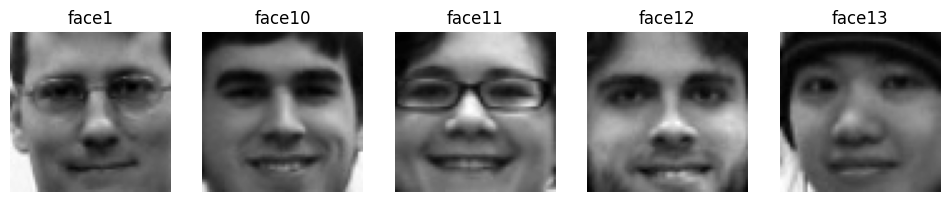

In [ ]:
plt.figure(figsize=(12,4))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(test_images[i].reshape(64,64),cmap='gray')
  plt.title(test_labels[i])
  plt.axis('off')
plt.show()

In [ ]:
mean_face = np.mean(train_images, axis=0)
print("Mean Face Shape:",mean_face.shape)

Mean Face Shape: (4096,)


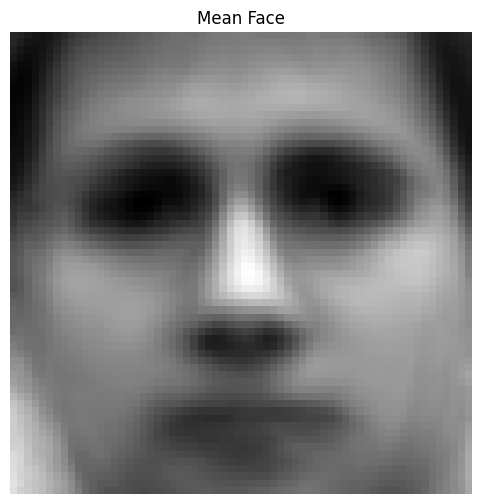

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(mean_face.reshape(64,64),cmap='gray')
plt.title("Mean Face")
plt.axis('off')
plt.show()

In [ ]:
A_train = train_images - mean_face
print(A_train.shape)

(36, 4096)


In [ ]:
A_test = test_images - mean_face
print(A_test.shape)

(36, 4096)


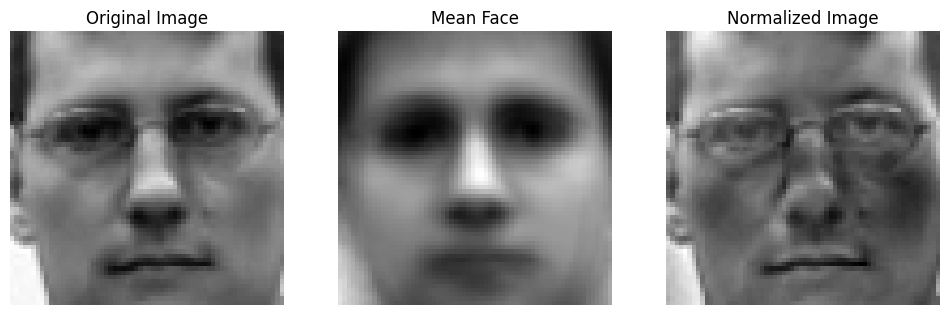

In [ ]:
plt.figure(figsize=(12,4))

# Original Image
plt.subplot(1,3,1)
plt.imshow(train_images[0].reshape(64,64),cmap='gray')
plt.title("Original Image")
plt.axis('off')

# Mean Face
plt.subplot(1,3,2)
plt.imshow(mean_face.reshape(64,64),cmap='gray')
plt.title("Mean Face")
plt.axis('off')

# Normalized Image
plt.subplot(1,3,3)
plt.imshow(A_train[0].reshape(64,64),cmap='gray')
plt.title("Normalized Image")
plt.axis('off')

plt.show()

In [ ]:
print("Average value after normalization:")
print(np.mean(A_train,axis=0))

Average value after normalization:
[-1.57898386e-15  0.00000000e+00  5.72381648e-15 ...  6.31593543e-15
 -5.52644350e-15 -9.47390314e-15]


Computing Eigenfaces using

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
NUM_EIGENFACES = 30

In [ ]:
pca = PCA(n_components=NUM_EIGENFACES)
train_features = pca.fit_transform(A_train)

In [ ]:
test_features = pca.transform(A_test)

In [ ]:
print("Training Feature Matrix :", train_features.shape)
print("Testing Feature Matrix :", test_features.shape)

Training Feature Matrix : (36, 30)
Testing Feature Matrix : (36, 30)


In [ ]:
eigenfaces = pca.components_
print(eigenfaces.shape)

(30, 4096)


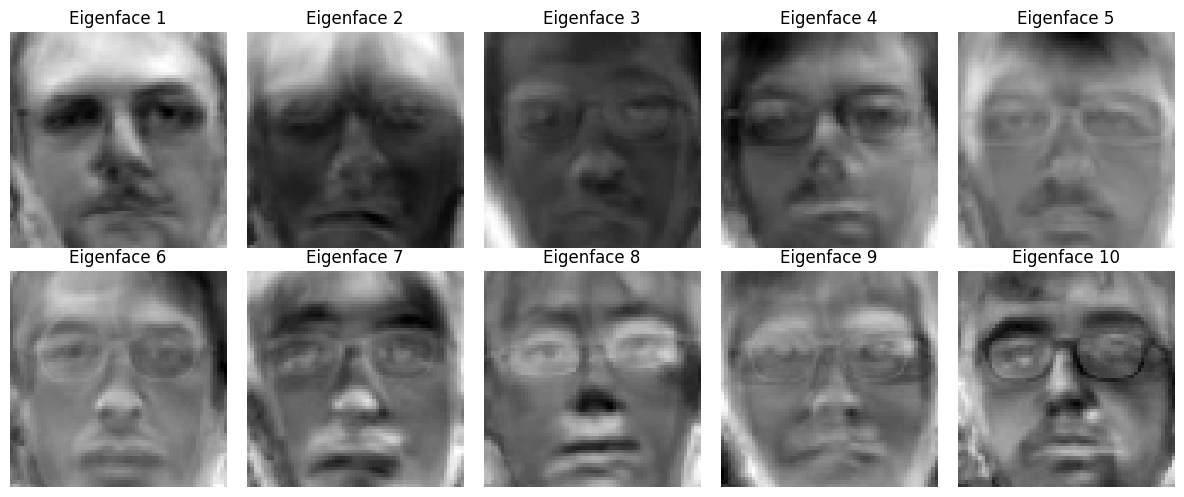

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(12,5))
for i, ax in enumerate(axes.flat):
  ax.imshow(eigenfaces[i].reshape(64,64),cmap='gray')
  ax.set_title(f"Eigenface {i+1}")
  ax.axis('off')
plt.tight_layout()
plt.show()

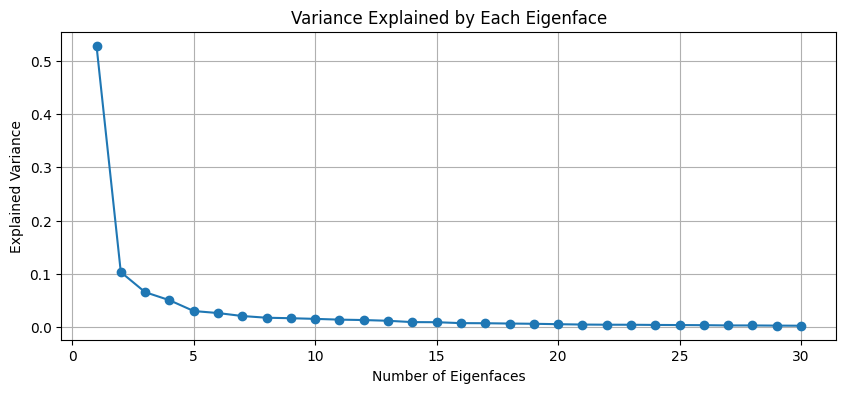

In [ ]:
variance = pca.explained_variance_ratio_
plt.figure(figsize=(10,4))
plt.plot(range(1,NUM_EIGENFACES+1),
         variance,
         marker = 'o')
plt.title("Variance Explained by Each Eigenface")
plt.xlabel("Number of Eigenfaces")
plt.ylabel("Explained Variance")
plt.grid(True)
plt.show()